# ROUND 2: EDA AND FEATURE ENGINEERING
# StayNest Hotel Booking Insight


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [3]:
# 1. Load Data
bookings = pd.read_csv('bookings.csv')
guests = pd.read_csv('guests.csv')
hotels = pd.read_csv('hotels.csv')
channels = pd.read_csv('channels.csv')
calendar = pd.read_csv('calendar.csv')

In [4]:
# Merge Datasets
df = bookings.merge(guests, on='guest_id', how='left') \
             .merge(hotels, on='hotel_id', how='left') \
             .merge(channels, on='channel_id', how='left') \
             .merge(calendar, on='stay_date', how='left')

In [5]:
# 2. Preprocessing & Data Cleaning
# Handle Data Quality Conditions
df['guest_origin'] = df['guest_origin'].fillna('Unknown')
df = df.drop_duplicates(subset=['booking_id'])
df['room_type'] = df['room_type'].str.strip().str.upper()

In [6]:
# Fix Invalid Stay Dates & Outlier Room Rates
df = df[pd.to_datetime(df['stay_date'], errors='coerce').notnull()]
df['booking_date'] = pd.to_datetime(df['booking_date'])
df['stay_date'] = pd.to_datetime(df['stay_date'])
df = df[df['stay_date'] >= df['booking_date']]

In [7]:
q_low = df['rate'].quantile(0.01)
q_high = df['rate'].quantile(0.99)
df['rate'] = np.clip(df['rate'], q_low, q_high)

In [8]:
# 3. Feature Engineering
df['lead_time'] = (df['stay_date'] - df['booking_date']).dt.days
df['is_cancelled'] = (df['status'] == 'Cancelled').astype(int)

/tmp/ipykernel_1390/3395547667.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='booking_channel', y='is_cancelled', ci=None)


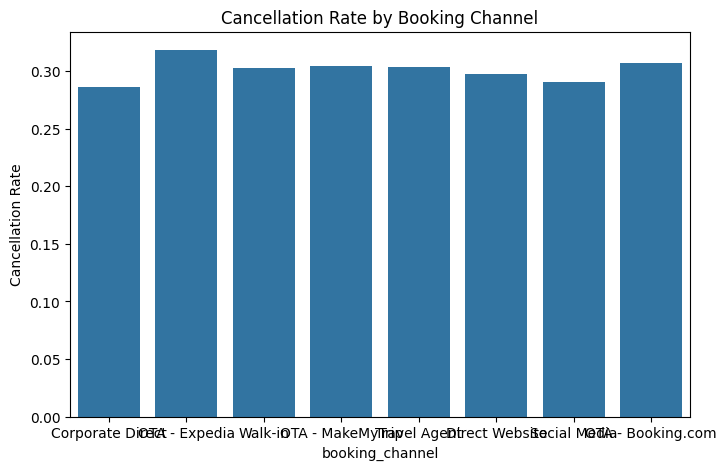

In [9]:
# 4. EDA Visualizations
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='booking_channel', y='is_cancelled', ci=None)
plt.title('Cancellation Rate by Booking Channel')
plt.ylabel('Cancellation Rate')
plt.show()

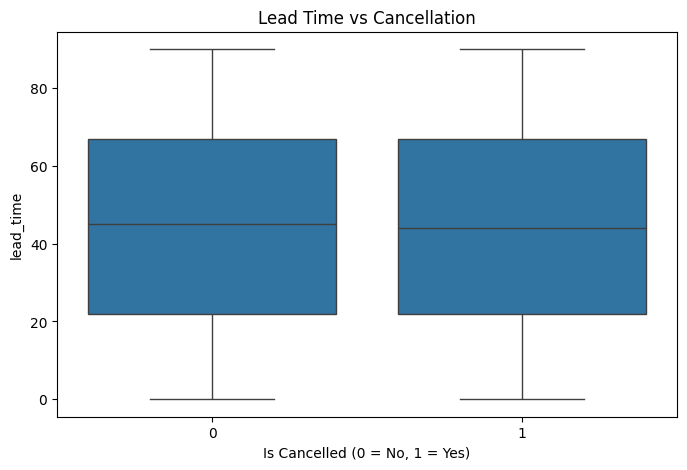

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='is_cancelled', y='lead_time')
plt.title('Lead Time vs Cancellation')
plt.xlabel('Is Cancelled (0 = No, 1 = Yes)')
plt.show()

/tmp/ipykernel_1390/123910016.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='season', y='is_cancelled', ci=None)


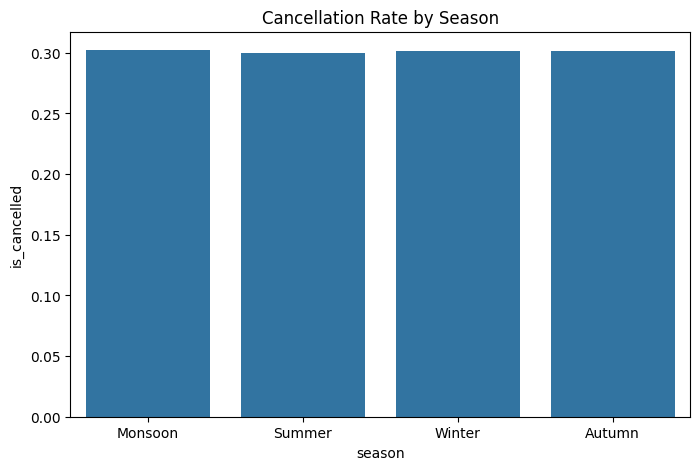

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='season', y='is_cancelled', ci=None)
plt.title('Cancellation Rate by Season')
plt.show()

/tmp/ipykernel_1390/1563981299.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='repeat_status', y='is_cancelled', ci=None)


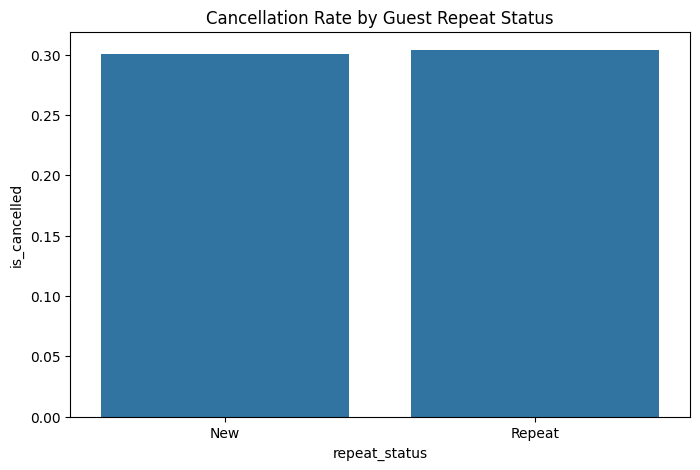

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='repeat_status', y='is_cancelled', ci=None)
plt.title('Cancellation Rate by Guest Repeat Status')
plt.show()

In [15]:
# 5. Modeling Setup (Predicting Cancellation)
features = ['lead_time', 'rate', 'booking_channel', 'guest_type', 'room_type', 'season', 'repeat_status', 'event']
X = df[features]
y = df['is_cancelled']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = ['lead_time', 'rate']
cat_cols = ['booking_channel', 'guest_type', 'room_type', 'season', 'repeat_status', 'event']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6467860906217071
F1-Score: 0.18363370677057964
              precision    recall  f1-score   support

           0       0.70      0.86      0.77      6662
           1       0.29      0.13      0.18      2828

    accuracy                           0.65      9490
   macro avg       0.50      0.50      0.48      9490
weighted avg       0.58      0.65      0.60      9490



# ROUND 3: DATA ANALYSIS USING EXCEL
# Python generation script to export structured workbook

In [16]:
# Prepare aggregated summary datasets for Excel Pivot Tables & Charts
excel_writer = pd.ExcelWriter('StayNest_Hotel_Analysis.xlsx', engine='openpyxl')

In [17]:
# Clean Data Sheet
df.to_excel(excel_writer, sheet_name='Cleaned_Data', index=False)

In [18]:
# Analysis 1: Cancellation by Channel
channel_summary = df.groupby('booking_channel').agg(
    Total_Bookings=('booking_id', 'count'),
    Cancellations=('is_cancelled', 'sum'),
    Cancellation_Rate=('is_cancelled', 'mean')
).reset_index()
channel_summary.to_excel(excel_writer, sheet_name='Channel_Analysis', index=False)

In [19]:
# Analysis 2: Lead-Time Analysis
lead_time_summary = df.groupby('is_cancelled').agg(
    Avg_Lead_Time=('lead_time', 'mean'),
    Median_Lead_Time=('lead_time', 'median')
).reset_index()
lead_time_summary.to_excel(excel_writer, sheet_name='LeadTime_Analysis', index=False)

In [20]:
# Analysis 3: Seasonal Occupancy
seasonal_summary = df.groupby('season').agg(
    Total_Bookings=('booking_id', 'count'),
    Occupied_Stays=('status', lambda x: (x == 'Completed').sum()),
    Avg_Rate=('rate', 'mean')
).reset_index()
seasonal_summary.to_excel(excel_writer, sheet_name='Seasonal_Analysis', index=False)

In [21]:
# Analysis 4: Guest-Type & Repeat Status Comparison
guest_summary = df.groupby(['guest_type', 'repeat_status']).agg(
    Total_Bookings=('booking_id', 'count'),
    Cancellation_Rate=('is_cancelled', 'mean')
).reset_index()
guest_summary.to_excel(excel_writer, sheet_name='Guest_Analysis', index=False)

In [22]:
# Analysis 5: Room Performance
room_summary = df.groupby('room_type').agg(
    Total_Bookings=('booking_id', 'count'),
    Avg_Rate=('rate', 'mean'),
    Cancellation_Rate=('is_cancelled', 'mean')
).reset_index()
room_summary.to_excel(excel_writer, sheet_name='Room_Performance', index=False)

In [23]:
# Analysis 6: Event Impact
event_summary = df.groupby('event').agg(
    Total_Bookings=('booking_id', 'count'),
    Avg_Rate=('rate', 'mean'),
    Cancellation_Rate=('is_cancelled', 'mean')
).reset_index()
event_summary.to_excel(excel_writer, sheet_name='Event_Impact', index=False)

excel_writer.close()